# 01 - Data download and reproducible subset (Project C19)

1. clones the repo,
2. downloads GoPro and DIV2K from their official sources,
3. selects the fixed train/val/test subsets (seed 42) with `src/make_subset.py`,
4. shows a few sample pairs as a sanity check.


## 1. Clone the repo and get the latest code

In [ ]:
%cd /content
!test -d C19_project || git clone https://github.com/zaynabahmad/C19_project.git
%cd /content/C19_project
!git pull
!ls src

## 2. Environment check 

In [1]:
!python --version
!nvidia-smi || echo "No GPU in this runtime"
!pip install -q -r requirements.txt

/bin/bash: line 1: python: command not found


Sat Nov 14 21:12:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.05              Driver Version: 560.35.05      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce GTX 1650 Ti     Off |   00000000:01:00.0 Off |                  N/A |
| N/A   41C    P8              3W /   50W |       9MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3. Download the datasets 

In [4]:
!python3 src/fetch_data.py --dataset div2k

data/raw/DIV2K_valid_HR.zip already complete.
Unpacking data/raw/DIV2K_valid_HR.zip ...
Done. Top-level contents of data/raw:
   .gitkeep
   DIV2K_valid_HR
   DIV2K_valid_HR.zip
   GOPRO_Large.zip


In [5]:
!python3 src/fetch_data.py --dataset gopro

  -> data/raw/GOPRO_Large.zip (remaining bytes: 9145680716)
Unpacking data/raw/GOPRO_Large.zip ...
Done. Top-level contents of data/raw:
   .gitkeep
   DIV2K_valid_HR
   DIV2K_valid_HR.zip
   GOPRO_Large.zip
   test
   train


## 4. Look at the real folder layo

In [7]:
!ls data/raw/train | head -3
!ls data/raw/train/$(ls data/raw/train | head -1)

GOPR0372_07_00
GOPR0372_07_01
GOPR0374_11_00


 blur   blur_gamma  'frames 7 offset 0.txt'   sharp


## 5. Select the subsets (writes data/subsets/gopro_subset.json and div2k_subset.json)

In [9]:
!python3 -m src.make_subset

GoPro root: data/raw
  train sequences: 22 (val held out: ['GOPR0372_07_00', 'GOPR0374_11_01', 'GOPR0881_11_00']), test sequences: 11
  pairs -> train: 365, val: 56, test: 223
DIV2K: 25 of 100 images selected (seed 42)


## 6. Sanity check: look at the first 3 training pairs

{'train': 365, 'val': 56, 'test': 223} val sequences: ['GOPR0372_07_00', 'GOPR0374_11_01', 'GOPR0881_11_00']


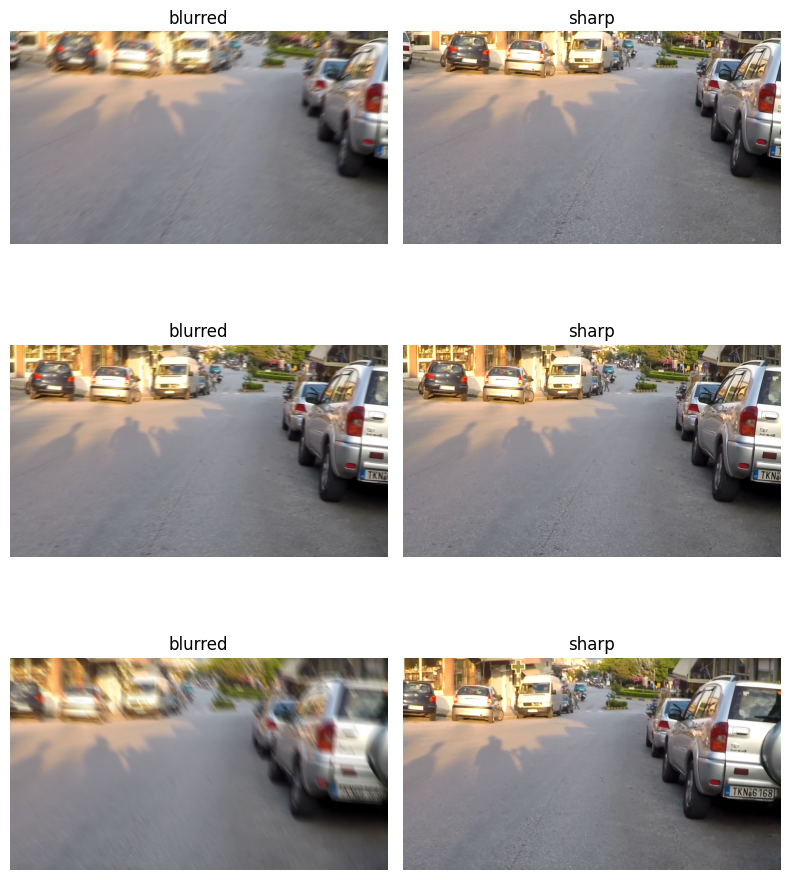

In [12]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

d = json.load(open("data/subsets/gopro_subset.json"))
root = Path(d["root"])
print({k: len(d[k]) for k in ("train", "val", "test")}, "val sequences:", d["val_sequences"])

fig, axes = plt.subplots(3, 2, figsize=(8, 10))
for row, pair in zip(axes, d["train"][:3]):
    row[0].imshow(Image.open(root / pair["blur"]));  row[0].set_title("blurred");  row[0].axis("off")
    row[1].imshow(Image.open(root / pair["sharp"])); row[1].set_title("sharp");    row[1].axis("off")
plt.tight_layout()
Path("results/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("results/figures/sample_pairs.png", dpi=100)
plt.show()

## 7. Download the files to commit (subset lists + sample figure)

ModuleNotFoundError: No module named 'google.colab'